# Лабораторная работа №4: байесовская сеть

Используем открытый датасет **Titanic**, уже знакомый по лабе №2:
[исходный CSV](https://github.com/datasciencedojo/datasets/blob/master/titanic.csv).
Один объект — пассажир, а не рейс или семья.
Самостоятельно зададим небольшой граф и изучим, как сведения о пассажире
меняют оценку вероятности выживания.

Для сети используем `pgmpy`: [оценка параметров](https://pgmpy.org/guides/parameter_estimation.html)
и [вероятностный вывод](https://pgmpy.org/examples/Inference_Discrete_BN.html).
Автоматический поиск структуры не нужен: граф задаём и объясняем сами.

In [ ]:
%pip install -q pandas numpy matplotlib seaborn networkx "pgmpy==1.1.2"

In [2]:
import warnings
warnings.simplefilter("ignore")

from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)

## 1. Знакомство с данными

| Переменная сети | Значение |
|---|---|
| `Sex` | Пол: `female`, `male` |
| `Pclass` | Класс билета: 1, 2, 3 |
| `Child` | 1, если возраст не больше 12 лет, иначе 0 |
| `FareGroup` | Цена билета: `low` ≤ 15, `medium` от 15 до 50, `high` > 50 |
| `Survived` | 1 — выжил, 0 — погиб |

Предполагаем связь выживания с полом, возрастной группой и классом билета,
а цены — с классом. Остальные столбцы для небольшой сети не нужны.

In [3]:
ROOT = Path.cwd()
if not (ROOT / "classification").exists():
    ROOT = ROOT.parent
df = pd.read_csv(ROOT / "classification/data/titanic.csv")
columns = ["Sex", "Pclass", "Age", "Fare", "Survived"]
print("Размер исходных данных:", df.shape)
print("Полных дубликатов:", df.duplicated().sum())
display(df[columns].head())
display(pd.DataFrame({
    "пропусков": df[columns].isna().sum(),
    "уникальных значений": df[columns].nunique(),
}))

Размер исходных данных: (891, 12)
Полных дубликатов: 0


,Sex,Pclass,Age,Fare,Survived
0,male,3,22.0,7.2500,0
1,female,1,38.0,71.2833,1
2,female,3,26.0,7.9250,1
3,female,1,35.0,53.1000,1
4,male,3,35.0,8.0500,0


,пропусков,уникальных значений
Sex,0,2
Pclass,0,3
Age,177,88
Fare,0,248
Survived,0,2


## 2. Подготовка данных

Для простой дискретной сети превращаем возраст и цену в категории.
Порог возраста 12 лет отделяет маленьких детей, а три диапазона цены различают
дешёвые, средние и дорогие билеты без большого числа состояний.
Границы заданы заранее, а не подбираются по выживанию.

Удаляем строки с пропусками в используемых столбцах. Это проще, чем приписывать
неизвестному возрасту категорию взрослого по медиане, но уменьшает выборку
и может сместить оценки: возраст известен не у всех пассажиров.
Одинаковые значения выбранных признаков не считаем дубликатами:
они могут принадлежать разным людям.

Здесь оцениваем вероятности по данным, а не качество классификатора,
поэтому обучаем сеть на всех оставшихся наблюдениях и не вводим train/test.

In [4]:
known = df.dropna(subset=columns).copy()
data = known[["Sex", "Pclass", "Survived"]].copy()
data["Child"] = (known["Age"] <= 12).astype(int)
data["FareGroup"] = pd.cut(
    known["Fare"], bins=[-np.inf, 15, 50, np.inf],
    labels=["low", "medium", "high"],
).astype(str)
data = data[["Sex", "Pclass", "Child", "FareGroup", "Survived"]]
print(f"Удалено строк: {len(df) - len(data)}, осталось: {len(data)}")
for column in data:
    print(f"\n{column}: {data[column].nunique()} состояний")
    print(data[column].value_counts().sort_index())
print(f"\nДоля выживших до удаления: {df['Survived'].mean():.3f}")
print(f"После удаления: {data['Survived'].mean():.3f}")

Удалено строк: 177, осталось: 714

Sex: 2 состояний
Sex
female    261
male      453
Name: count, dtype: int64

Pclass: 3 состояний
Pclass
1    186
2    173
3    355
Name: count, dtype: int64

Child: 2 состояний
Child
0    645
1     69
Name: count, dtype: int64

FareGroup: 3 состояний
FareGroup
high      138
low       350
medium    226
Name: count, dtype: int64

Survived: 2 состояний
Survived
0    424
1    290
Name: count, dtype: int64

Доля выживших до удаления: 0.384
После удаления: 0.406


n  probability
Sex    Pclass Child                  
female 1      0       84        0.976
              1        1        0.000
       2      0       66        0.909
              1        8        1.000
       3      0       79        0.456
              1       23        0.478
male   1      0       98        0.378
              1        3        1.000
       2      0       90        0.067
              1        9        1.000
       3      0      228        0.127
              1       25        0.360

FareGroup,high,low,medium
Pclass,,,
1,127,4,55
2,7,86,80
3,4,260,91


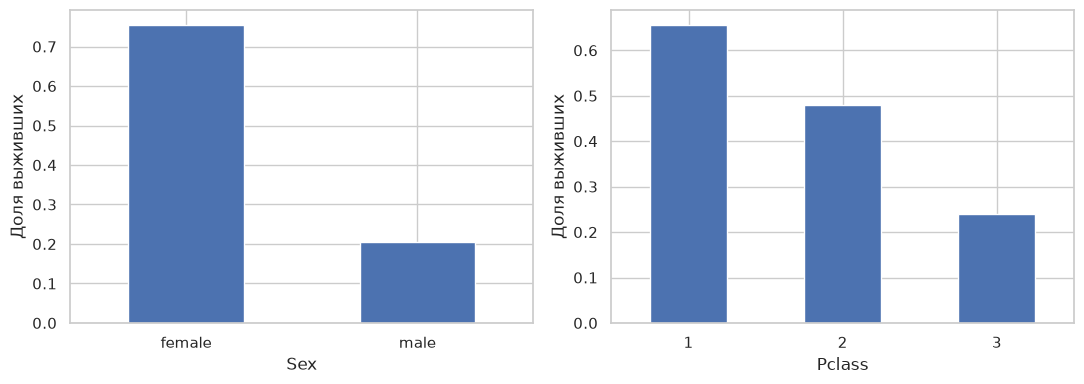

In [5]:
survival_groups = data.groupby(["Sex", "Pclass", "Child"])["Survived"].agg(
    n="size", probability="mean",
)
display(survival_groups.round(3))
display(pd.crosstab(data["Pclass"], data["FareGroup"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
data.groupby("Sex")["Survived"].mean().plot.bar(ax=axes[0], rot=0)
data.groupby("Pclass")["Survived"].mean().plot.bar(ax=axes[1], rot=0)
for ax in axes:
    ax.set_ylabel("Доля выживших")
plt.tight_layout()
plt.show()

**Вывод.** Из 891 пассажира оставили 714: у 177 неизвестен возраст.
После удаления доля выживших выросла с 38.4% до 40.6%, поэтому выборка уже отличается
от исходной. У переменных всего 2–3 состояния, но этого недостаточно для надёжности
каждой условной вероятности: из 69 детей только одна девочка первого класса.

В таблице выживания есть все 12 сочетаний пола, класса и возрастной группы,
но несколько групп содержат лишь 1–9 человек. Для них частоты 0 или 1
нельзя считать надёжной оценкой будущих исходов. Сохраняем небольшое число состояний,
а редкие сочетания явно учитываем при интерпретации.

## 3. Вопросы до построения сети

1. Как изменится вероятность выживания, если известно, что пассажир — женщина?
2. Какова вероятность выживания женщины из первого класса?
3. Как изменится вероятность выживания, если известна только высокая цена билета?

Во всех случаях сравним результат с вероятностью выживания без дополнительных сведений.
Отдельно последовательно добавим сведения: мужчина → третий класс → ребёнок.

## 4. Структура сети

Задаём четыре ребра:

- `Sex → Survived`: при спасении пол мог влиять на приоритет посадки в шлюпки.
- `Child → Survived`: такой же приоритет мог быть у детей.
- `Pclass → Survived`: класс связан с расположением кают и доступом к путям эвакуации.
- `Pclass → FareGroup`: тариф связан с категорией размещения; цена помогает косвенно судить о классе.

Пол, возрастная группа и билет известны до катастрофы, поэтому направляем первые три
стрелки к исходу. Последнее ребро отражает предположение о формировании тарифа,
а не вывод из одной корреляции. Сам граф предложен как гипотеза, а не доказанная причинная схема.

Граф ацикличен. Он задаёт разложение:

$$P(S,C,H,F,Y) = P(S)P(C)P(H)P(F\mid C)P(Y\mid S,C,H),$$

где $S$ — пол, $C$ — класс, $H$ — ребёнок, $F$ — группа цены, $Y$ — выживание.

**Упрощения:** корневые `Sex`, `Pclass`, `Child` считаются независимыми,
а цена не добавляет информации о выживании при уже известном классе.
В реальных данных эти предположения могут нарушаться; это ограничение небольшой сети.

Граф является DAG: True


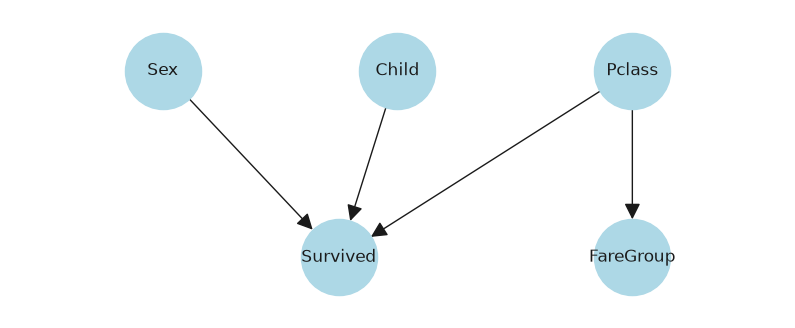

In [6]:
edges = [
    ("Sex", "Survived"),
    ("Child", "Survived"),
    ("Pclass", "Survived"),
    ("Pclass", "FareGroup"),
]
model = DiscreteBayesianNetwork(edges)
print("Граф является DAG:", nx.is_directed_acyclic_graph(model))

positions = {
    "Sex": (0, 1), "Child": (2, 1), "Pclass": (4, 1),
    "Survived": (1.5, 0), "FareGroup": (4, 0),
}
plt.figure(figsize=(10, 4))
nx.draw_networkx(
    model, pos=positions, node_size=3000, node_color="lightblue",
    arrowsize=24, font_size=12, margins=0.25,
)
plt.axis("off")
plt.show()

## 5. Условные вероятности

Оцениваем таблицы условных вероятностей (**CPD**) по частотам:
например, `P(Survived=1 | Sex, Pclass, Child)` — доля выживших в соответствующей группе.
Используем оценку максимального правдоподобия без дополнительных методов сглаживания.
`check_model()` проверяет согласованность таблиц и сумму вероятностей.

In [7]:
model.fit(data)
print("Таблицы вероятностей корректны:", model.check_model())

for variable in ["FareGroup", "Survived"]:
    cpd = model.get_cpds(variable)
    print(f"\nCPD для {variable}:")
    display(cpd.to_dataframe())

Таблицы вероятностей корректны: True

CPD для FareGroup:


FareGroup,high,low,medium
Pclass,,,
1,0.682796,0.021505,0.295699
2,0.040462,0.497110,0.462428
3,0.011268,0.732394,0.256338



CPD для Survived:


Survived                    0         1
Child Pclass Sex                       
0     1      female  0.023810  0.976190
             male    0.622449  0.377551
      2      female  0.090909  0.909091
             male    0.933333  0.066667
      3      female  0.544304  0.455696
             male    0.872807  0.127193
1     1      female  1.000000  0.000000
             male    0.000000  1.000000
      2      female  0.000000  1.000000
             male    0.000000  1.000000
      3      female  0.521739  0.478261
             male    0.640000  0.360000

In [8]:
cpd = model.get_cpds("Survived")
comparison = survival_groups.copy()
comparison["CPD"] = [
    cpd.get_value(Survived=1, Sex=sex, Pclass=pclass, Child=child)
    for sex, pclass, child in comparison.index
]
display(comparison.round(4))
print("CPD совпадает с частотами:",
      np.allclose(comparison["probability"], comparison["CPD"]))

n  probability     CPD
Sex    Pclass Child                          
female 1      0       84       0.9762  0.9762
              1        1       0.0000  0.0000
       2      0       66       0.9091  0.9091
              1        8       1.0000  1.0000
       3      0       79       0.4557  0.4557
              1       23       0.4783  0.4783
male   1      0       98       0.3776  0.3776
              1        3       1.0000  1.0000
       2      0       90       0.0667  0.0667
              1        9       1.0000  1.0000
       3      0      228       0.1272  0.1272
              1       25       0.3600  0.3600

CPD совпадает с частотами: True


**Проверка по данным.** CPD выживания точно совпадают с долями выживших
в соответствующих группах. Среди взрослых женщин первого класса выжили 82 из 84
(97.6%), среди взрослых мужчин третьего класса — 29 из 228 (12.7%).
Цена тоже согласуется с классом: дорогой билет у 68.3% пассажиров первого класса
и лишь у 1.1% пассажиров третьего.

**Необычный результат:** для девочек первого класса вероятность выживания равна 0.
Это одна погибшая пассажирка, а не свидетельство низких шансов всей группы.
Вероятности 1 у мальчиков первого и второго классов тоже основаны лишь на 3 и 9 детях.
Без сглаживания оценка по частотам воспроизводит такие крайние значения.
Данных хватает для общей иллюстрации сети, но для редких групп выводы неустойчивы.

## 6. Вероятностный вывод

`VariableElimination` вычисляет распределение по сети: фиксирует известные значения
и суммирует по неизвестным. Evidence — это наблюдение, а не вмешательство.

In [9]:
inference = VariableElimination(model)

def survival_probability(engine, evidence=None):
    result = engine.query(
        variables=["Survived"], evidence=evidence, show_progress=False,
    )
    return float(result.get_value(Survived=1))

prior = survival_probability(inference)
questions = [
    ("Женщина", {"Sex": "female"}),
    ("Женщина, 1 класс", {"Sex": "female", "Pclass": 1}),
    ("Дорогой билет", {"FareGroup": "high"}),
]
answers = pd.DataFrame([
    {"условие": label, "до evidence": prior,
     "после evidence": survival_probability(inference, evidence)}
    for label, evidence in questions
]).set_index("условие")
answers["изменение, п.п."] = (answers["после evidence"] - prior) * 100
display(answers.round(4))
print(f"Доля выживших в данных: {data['Survived'].mean():.4f}")
print(f"Вероятность без evidence по сети: {prior:.4f}")

class_given_fare = inference.query(
    variables=["Pclass"], evidence={"FareGroup": "high"}, show_progress=False,
)
print("Распределение класса при дорогом билете:")
print(class_given_fare)

,до evidence,после evidence,"изменение, п.п."
условие,,,
Женщина,0.3922,0.6798,28.7613
"Женщина, 1 класс",0.3922,0.8819,48.9685
Дорогой билет,0.3922,0.5819,18.9734


Доля выживших в данных: 0.4062
Вероятность без evidence по сети: 0.3922
Распределение класса при дорогом билете:
+-----------+---------------+
| Pclass    |   phi(Pclass) |
+===========+===============+
| Pclass(1) |        0.9203 |
+-----------+---------------+
| Pclass(2) |        0.0507 |
+-----------+---------------+
| Pclass(3) |        0.0290 |
+-----------+---------------+


**Ответы на вопросы:**

1. Информация о женском поле повышает вероятность выживания с **39.2% до 68.0%**:
   сеть использует CPD выживания для женщин, усредняя по неизвестным классу и возрастной группе.
2. Для женщины первого класса вероятность **88.2%**. Класс уточняет группу
   с более высокой выживаемостью. Результат ниже 97.6% для взрослых женщин этого класса:
   возрастная группа неизвестна, а для единственной девочки в данных исход равен 0.
3. При дорогом билете вероятность **58.2%**. В сети цена связана с исходом
   через класс: дорогой билет повышает вероятность первого класса до **92.0%**.
   Это косвенная информация, а не доказательство влияния самой цены.

Без evidence сеть даёт **39.2%**, а наблюдаемая доля выживших — **40.6%**.
Они не обязаны совпадать: сеть усредняет CPD с независимыми распределениями пола,
класса и возрастной группы, а в данных эти признаки могут зависеть друг от друга.
Это видимое следствие выбранного упрощения структуры.

## 7. Последовательное добавление evidence

Следим за одной переменной — `Survived`. На каждом шаге сохраняем предыдущие сведения
и добавляем одно новое. Показываем обе вероятности: погиб и выжил.

,P(выжил),P(погиб)
известно,,
Ничего не известно,0.3922,0.6078
Мужчина,0.2265,0.7735
"Мужчина, 3 класс",0.1497,0.8503
"Мужчина, 3 класс, ребёнок",0.3600,0.6400


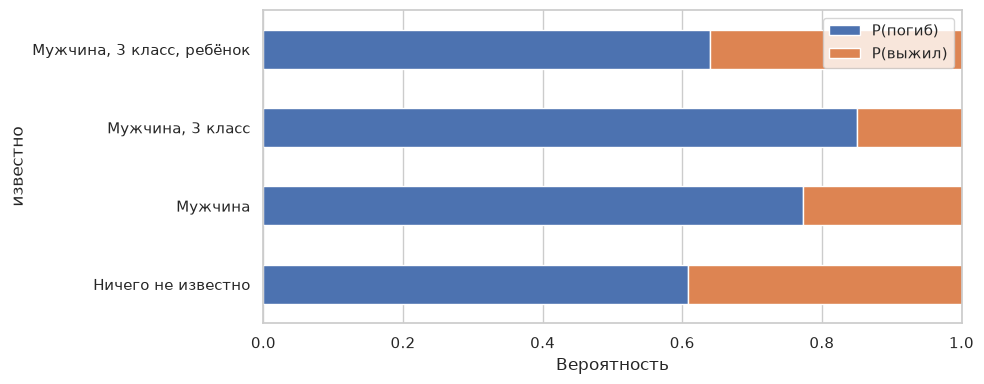

In [10]:
steps = [
    ("Ничего не известно", None),
    ("Мужчина", {"Sex": "male"}),
    ("Мужчина, 3 класс", {"Sex": "male", "Pclass": 3}),
    ("Мужчина, 3 класс, ребёнок", {"Sex": "male", "Pclass": 3, "Child": 1}),
]
evidence_table = pd.DataFrame([
    {"известно": label, "P(выжил)": survival_probability(inference, evidence)}
    for label, evidence in steps
]).set_index("известно")
evidence_table["P(погиб)"] = 1 - evidence_table["P(выжил)"]
display(evidence_table.round(4))
evidence_table[["P(погиб)", "P(выжил)"]].plot.barh(
    stacked=True, figsize=(10, 4), xlim=(0, 1), xlabel="Вероятность",
)
plt.tight_layout()
plt.show()

Последовательность вероятностей выживания: **39.2% → 22.6% → 15.0% → 36.0%**.
Сведения о мужском поле и третьем классе снижают оценку, а информация о ребёнке
повышает её: среди мальчиков третьего класса выжили 9 из 25.

Все три переменные — родители `Survived`, поэтому каждое уточнение меняет
используемую условную вероятность. Evidence не обязано только повышать или только
понижать вероятность: направление изменения зависит от новой информации.

## 8. Удаление ребра

Удалим `Pclass → Survived` и заново оценим CPD по тем же данным:
простого удаления стрелки недостаточно, поскольку набор родителей выживания изменился.
Повторим запрос для мужчины третьего класса и сравним с исходной сетью.

In [11]:
reduced_edges = [edge for edge in edges if edge != ("Pclass", "Survived")]
reduced_model = DiscreteBayesianNetwork(reduced_edges)
reduced_model.fit(data)
print("Изменённая сеть корректна:", reduced_model.check_model())
reduced_inference = VariableElimination(reduced_model)
evidence = {"Sex": "male", "Pclass": 3}
structure_table = pd.DataFrame({
    "P(выжил)": [survival_probability(inference, evidence),
                 survival_probability(reduced_inference, evidence)],
}, index=["Исходная сеть", "Без Pclass → Survived"])
display(structure_table.round(4))

Изменённая сеть корректна: True


,P(выжил)
Исходная сеть,0.1497
Без Pclass → Survived,0.2112


После удаления ребра вероятность для мужчины третьего класса выросла
с **15.0% до 21.1%**. Теперь CPD выживания зависит только от пола и возрастной группы:
в неё входят мужчины всех классов, в том числе первого с более высокой выживаемостью.
В изменённом графе `Pclass` и `Survived` находятся в разных компонентах,
поэтому указание класса вообще перестаёт влиять на результат.

Структура определяет, какие сведения могут менять распределение и по каким
группам оцениваются CPD. Значит, одинаковые данные при разных графах могут дать
разный вывод. Само изменение результата не доказывает правильность направления ребра.

## 9. Можно ли считать сеть причинной?

**Нет, по этой работе причинность не установлена.** Мы предложили направления рёбер
по смыслу переменных и оценили вероятности по наблюдательным данным.
Возможны неучтённые причины: расположение каюты, действия экипажа,
местонахождение пассажира и доступ к конкретной шлюпке.

Стрелки от пола и возрастной группы к выживанию выражают гипотезу о правилах спасения,
а не доказанный эффект изменения признака. Класс может быть связан с исходом через доступ
к эвакуации, но эти промежуточные переменные в сети отсутствуют.
Наблюдение дорогого билета помогает судить о классе; само увеличение цены
не означает изменения шанса выжить.

По одним наблюдениям направление ребра часто нельзя однозначно восстановить:
разные DAG могут описывать одни и те же зависимости. Нужны предметные основания,
временной порядок или дополнительные данные. Вычисленные вероятности относятся
к похожим пассажирам в этих данных, а не к результату вмешательства.

## 10. Итоги и ограничения

- Построена сеть из пяти переменных и четырёх объяснённых рёбер; граф является DAG,
  а CPD корректны и совпадают с соответствующими частотами.
- Наиболее заметно сведения о поле и классе меняют вероятность выживания:
  39.2% без evidence, 68.0% для женщины и 88.2% для женщины первого класса.
- Цена даёт косвенную информацию через класс. Последовательное evidence может
  как снижать, так и повышать вероятность: для мужчины третьего класса сведения
  о детском возрасте повысили её с 15.0% до 36.0%.
- Удаление связи класса с выживанием изменило один и тот же запрос с 15.0% до 21.1%.
  Вывод зависит от выбранной структуры.
- Ограничения: удалены 177 строк с неизвестным возрастом, некоторые группы очень малы,
  возраст и цена огрублены, корневые переменные считаются независимыми,
  многие обстоятельства спасения не учтены. Сеть не доказана как причинная модель.